# Figure: Dataset Size vs Performance

This notebook produces the dataset-size figure from `nb_ds_size.ipynb`.

Raw `eval_sweeps` results are cached in `./output/` to avoid re-running expensive predictions.
Delete the cached files to force re-evaluation.

In [13]:
from os.path import dirname, abspath, join
from os import makedirs
import sys
import numpy as np
import pandas as pd
import re
import json
from omegaconf import OmegaConf
import os
import glob
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from matplotlib.colors import LogNorm

root_path = dirname(abspath("./"))
sys.path.append(root_path)
from proT.evaluation.predict import *
from proT.evaluation.metrics import *
from proT.evaluation.eval_sweeps import eval_sweeps

# plotting standard settings
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 18
plt.rcParams['xtick.labelsize'] = 16
plt.rcParams['ytick.labelsize'] = 16
plt.rcParams['legend.fontsize'] = 14
plt.rcParams['figure.figsize'] = (6, 6)
plt.rcParams['lines.linewidth'] = 1.5
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=sns.color_palette('colorblind'))
plt.rcParams['lines.linewidth'] = 2.0

output_dir = "./output"
makedirs(output_dir, exist_ok=True)

## Data: Main Sweep (df_tot)

Cached to `./output/ds_size_tot.parquet`. Delete the file to re-run evaluation.

In [14]:
tot_cache_path = join(output_dir, "ds_size_tot.parquet")

if os.path.exists(tot_cache_path):
    print(f"Loading cached df_tot from {tot_cache_path}")
    df_tot = pd.read_parquet(tot_cache_path)
else:
    print("No cached df_tot found. Running eval_sweeps...")
    datadir_path = "../data/input"
    experiment_dir = "../experiments/ds_size/ds_size_proT_ishigami_sum_52584861"
    df_tot = eval_sweeps(
        filepath=experiment_dir,
        datadir_path=datadir_path
    )
    df_tot.to_parquet(tot_cache_path, index=False)
    print(f"Saved df_tot to {tot_cache_path}")

df_tot.head()

Loading cached df_tot from ./output\ds_size_tot.parquet


,index,R2,MSE,MAE,RMSE,model_folder,level_3,level_2,level_1,level_0
0,0,0.987476,0.000010,0.002761,0.003183,combo_max_data_size_12000_max_epochs_200,combo_max_data_size_12000_max_epochs_200,combinations,runs,sweeper
1,1,0.976474,0.000006,0.001670,0.002395,combo_max_data_size_12000_max_epochs_200,combo_max_data_size_12000_max_epochs_200,combinations,runs,sweeper
2,2,0.986936,0.000009,0.002364,0.002925,combo_max_data_size_12000_max_epochs_200,combo_max_data_size_12000_max_epochs_200,combinations,runs,sweeper
3,3,0.988207,0.000010,0.002489,0.003150,combo_max_data_size_12000_max_epochs_200,combo_max_data_size_12000_max_epochs_200,combinations,runs,sweeper
4,4,0.746397,0.000011,0.002445,0.003326,combo_max_data_size_12000_max_epochs_200,combo_max_data_size_12000_max_epochs_200,combinations,runs,sweeper


## Post-processing

Extract columns (Fusion, Epochs, DS Size) and combine into a single `df_plot`.

In [15]:
df_tot['Fusion'] = df_tot['level_0'].apply(lambda x: re.search(r'(sum|cat)', x).group(1) if re.search(r'(sum|cat)', x) else None)
df_tot["Epochs"] = df_tot['model_folder'].apply(lambda x: re.search(r'_(\d+)$', x).group(1) if re.search(r'_(\d+)$', x) else None).astype(int)
df_tot["DS Size"] = df_tot['model_folder'].apply(lambda x: re.search(r'_(\d+)_', x).group(1) if re.search(r'_(\d+)$', x) else None)

## Data: Rarity Index Distribution per Train Split

The train splits used in the sweep are obtained by truncating the train file
(`X[:max_data_size]`, see `ProcessDataModule.prepare_data`), so they can be
reproduced exactly here.

The rarity index of a sample is the **last value of its target sequence**
(`y[:, -1, 0]`). The `rarity` column stored in the dataset (`y[:, 0, 1]`) is a
50-bin histogram frequency of that same quantity, so it takes only 42 distinct
values and is unsuited for a density plot. Set `use_stored_rarity = True` to
use it anyway.

In [16]:
data_dir = "../data/input/ishigami_ideal_ds"
y_train = np.load(join(data_dir, "train_data.npz"), allow_pickle=True)["y"]

use_stored_rarity = False
if use_stored_rarity:
    rarity_all = y_train[:, 0, 1]     # binned rarity frequency (42 distinct values)
    rarity_label = r"Stored rarity frequency"
else:
    rarity_all = y_train[:, -1, 0]    # last value of the target sequence
    rarity_label = r"Rarity Index"

# splits reproduce the dataloader truncation X[:max_data_size]
split_sizes = [120, 1200, 12000]
split_order = [str(n) for n in split_sizes] + ["full"]

df_rarity = pd.concat(
    [pd.DataFrame({"Rarity Index": rarity_all[:n], "Train Split Size": str(n)}) for n in split_sizes]
    + [pd.DataFrame({"Rarity Index": rarity_all, "Train Split Size": "full"})],
    ignore_index=True,
)

df_rarity.groupby("Train Split Size")["Rarity Index"].agg(["count", "min", "max", "std"]).loc[split_order]

,count,min,max,std
Train Split Size,,,,
120,120,-0.550781,0.99070,0.271932
1200,1200,-0.873809,0.99398,0.262034
12000,12000,-1.000000,1.00000,0.256446
full,12794,-1.000000,1.00000,0.257021


## Figure (pair panel)

- (a) Train split size x epochs -> test MAE
- (b) Density of the rarity index per train split on a log density axis (so the
  tails stay visible), with a boxplot-style support strip underneath
  (box = IQR, whiskers = full min-max range, i.e. the support).

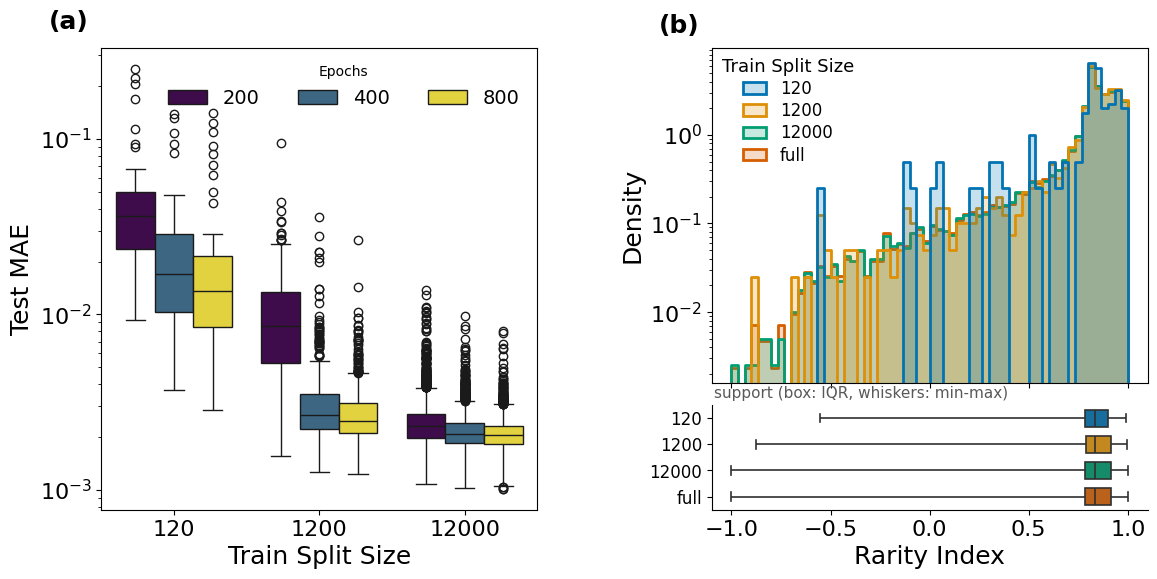

In [17]:
save_dir = "./figures"
makedirs(save_dir, exist_ok=True)

# --- knobs -------------------------------------------------------------
density_kind = "hist"   # "hist" (empirical tails) or "kde" (smooth)
density_log = True      # log density axis to expose the tails
density_fill = True     # translucent fill under the densities
fill_alpha = 0.22
n_bins = 60

# colorblind-safe palette (seaborn 'colorblind')
split_colors = dict(zip(split_order, sns.color_palette("colorblind", len(split_order))))

fig = plt.figure(figsize=(13.5, 6))
gs = gridspec.GridSpec(1, 2, figure=fig, wspace=0.40)
gs_right = gridspec.GridSpecFromSubplotSpec(
    2, 1, subplot_spec=gs[1], height_ratios=[3.2, 1.0], hspace=0.10
)

axL = fig.add_subplot(gs[0])
axR = fig.add_subplot(gs_right[0])
axS = fig.add_subplot(gs_right[1], sharex=axR)

# --- (a) test MAE boxplot -------------------------------------------------
ds_order = [str(n) for n in split_sizes]
sns.boxplot(
    df_tot,
    x="DS Size",
    y="MAE",
    hue="Epochs",
    order=ds_order,
    ax=axL,
    palette="viridis",
    legend=True
)
axL.set_xlabel(r"Train Split Size")
axL.set_ylabel(r"Test MAE")
axL.set_yscale("log")
axL.legend(title="Epochs", frameon=False, loc="upper right", ncol=3)

# --- (b top) rarity index density ----------------------------------------
if density_kind == "hist":
    bins = np.linspace(
        df_rarity["Rarity Index"].min(), df_rarity["Rarity Index"].max(), n_bins + 1
    )
    sns.histplot(
        data=df_rarity,
        x="Rarity Index",
        hue="Train Split Size",
        hue_order=split_order,
        palette=split_colors,
        bins=bins,
        stat="density",
        common_norm=False,
        element="step",
        fill=density_fill,
        alpha=fill_alpha,
        linewidth=2.0,
        ax=axR
    )
else:
    sns.kdeplot(
        data=df_rarity,
        x="Rarity Index",
        hue="Train Split Size",
        hue_order=split_order,
        palette=split_colors,
        common_norm=False,
        fill=density_fill,
        alpha=fill_alpha,
        linewidth=2.0,
        ax=axR
    )

if density_log:
    axR.set_yscale("log")

axR.set_xlabel("")
axR.set_ylabel(r"Density")
axR.tick_params(labelbottom=False)
sns.move_legend(
    axR,
    loc="upper left",
    title="Train Split Size",
    frameon=False,
    ncol=1,
    fontsize=12,
    title_fontsize=13,
    handlelength=1.4,
    labelspacing=0.25,
    borderaxespad=0.2
)

# --- (b bottom) support strip (boxplot style) ----------------------------
# whis=(0, 100) makes the whiskers span the full range, i.e. the support
sns.boxplot(
    data=df_rarity,
    x="Rarity Index",
    y="Train Split Size",
    order=split_order,
    hue="Train Split Size",
    hue_order=split_order,
    palette=split_colors,
    legend=False,
    orient="h",
    whis=(0, 100),
    width=0.65,
    linewidth=1.2,
    fliersize=0,
    ax=axS
)
axS.set_xlabel(rarity_label)
axS.set_ylabel("")
axS.tick_params(axis="y", labelsize=12)
axS.spines["top"].set_visible(False)
axS.spines["right"].set_visible(False)
axS.text(
    0.005, 1.04, "support (box: IQR, whiskers: min-max)",
    transform=axS.transAxes, fontsize=11, va="bottom", color="0.35"
)

# --- panel tags -----------------------------------------------------------
for ax_, tag in zip((axL, axR), ("(a)", "(b)")):
    ax_.text(-0.12, 1.03, tag, transform=ax_.transAxes, fontsize=18, fontweight="bold", va="bottom")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_ds_size_pair.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()

## Numbers for the text: median test MAE

Exact medians of the boxes in panel (a), i.e. `median(MAE)` per
(train split size, epochs). Saved to `./output/ds_size_median_mae.csv`
and as a LaTeX table to `./output/ds_size_median_mae.tex`.

In [18]:
df_med = df_tot.copy()
df_med["DS Size"] = df_med["DS Size"].astype(int)

# medians exactly as drawn by the boxplot in panel (a)
median_table = df_med.pivot_table(
    index="DS Size", columns="Epochs", values="MAE", aggfunc="median"
).sort_index()

# full summary (count / median / mean / std) for reference
summary_table = (
    df_med.groupby(["DS Size", "Epochs"])["MAE"]
    .agg(["count", "median", "mean", "std"])
    .sort_index()
)

# relative improvement of the median w.r.t. the 200-epoch run of the same split
rel_change = (median_table.div(median_table[median_table.columns.min()], axis=0) - 1.0) * 100.0

median_table.to_csv(join(output_dir, "ds_size_median_mae.csv"), float_format="%.6f")
with open(join(output_dir, "ds_size_median_mae.tex"), "w") as fh:
    fh.write(
        median_table.to_latex(
            float_format="%.5f",
            caption="Median test MAE per train split size and number of epochs.",
            label="tab:ds_size_median_mae",
        )
    )

print("Median test MAE (rows: train split size, cols: epochs)")
print(median_table.round(5).to_string())
print("\nChange of the median vs 200 epochs [%]")
print(rel_change.round(1).to_string())
print("\nFull summary")
print(summary_table.round(5).to_string())

median_table

Median test MAE (rows: train split size, cols: epochs)
Epochs       200      400      800
DS Size                           
120      0.03640  0.01700  0.01359
1200     0.00857  0.00267  0.00247
12000    0.00231  0.00208  0.00204

Change of the median vs 200 epochs [%]
Epochs   200   400   800
DS Size                 
120      0.0 -53.3 -62.7
1200     0.0 -68.8 -71.1
12000    0.0  -9.9 -11.5

Full summary
                count   median     mean      std
DS Size Epochs                                  
120     200        48  0.03640  0.05223  0.05374
        400        48  0.01700  0.02812  0.03145
        800        48  0.01359  0.02639  0.03243
1200    200       480  0.00857  0.01027  0.00741
        400       480  0.00267  0.00346  0.00303
        800       480  0.00247  0.00295  0.00181
12000   200      3041  0.00231  0.00249  0.00092
        400      3041  0.00208  0.00218  0.00058
        800      3041  0.00204  0.00211  0.00049


Epochs,200,400,800
DS Size,,,
120,0.036404,0.016996,0.013592
1200,0.008568,0.002669,0.002472
12000,0.002310,0.002080,0.002043


## Figure: DS Size × Epochs → Test MAE

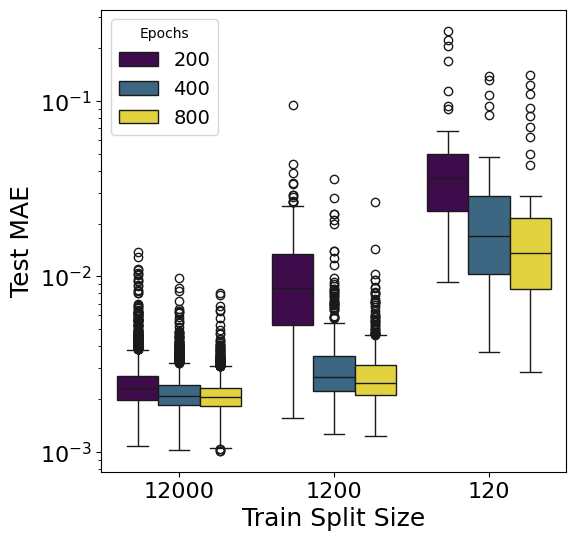

In [19]:
save_dir = "./figures"
makedirs(save_dir, exist_ok=True)

fig, ax = plt.subplots()


# Plot the boxplot with the custom palette
sns.boxplot(
    df_tot,
    x="DS Size",
    y="MAE",
    hue="Epochs",
    ax=ax,
    palette="viridis",
    legend=True
)

ax.set_xlabel(r"Train Split Size")
ax.set_ylabel(r"Test MAE")
ax.set_yscale("log")

# --- Save in multiple formats ---
for fmt in ["pdf", "svg", "png"]:
    out_path = join(save_dir, f"fig_ds_size.{fmt}")
    fig.savefig(out_path, format=fmt, bbox_inches="tight", dpi=360)

plt.show()